# MOD10 · Class 4 — Predicting a number - Regression

**Members of Group :** Adrien ROUILLON, Paul MORAND

**Data set :** Spotify

---

## Step 0 – Execute the code of previous sessions



---

Importing the database

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/Adrien-Rouillon/Machine-learning---SpotifyDB/refs/heads/main/spotify_artist_streaming_2020_2025.csv"
df = pd.read_csv(url)


The function below generates errors into the DB thanks to an AI algorithm.

In [53]:
def add_noise(df, seed=42):  # return a messy copy of a clean DataFrame
    rng = np.random.default_rng(seed)  # fixed seed -> same mess every run
    out = df.copy(deep=True)  # work on a deep copy so df is never modified
    num_cols = out.select_dtypes("number").columns.tolist()  # numeric columns available to corrupt
    if len(num_cols) < 2:  # need at least two numeric columns
        raise ValueError("df needs at least 2 numeric columns")  # fail loudly instead of guessing
    miss_cols = num_cols[:2]  # first two numeric columns get missing values
    out_col = num_cols[0]  # first numeric column gets outliers
    text_col = num_cols[2] if len(num_cols) > 2 else num_cols[1]  # third (or second) becomes text
    n = len(out)  # number of original rows

    # --- extreme outliers ---
    out_idx = rng.choice(out.index, size=3, replace=False)  # pick 3 rows to corrupt
    col = out[out_col].astype(float)  # float copy so large values fit
    col.loc[out_idx] = col.mean() + 20 * col.std() * rng.choice([-1, 1], size=3)  # push Â±20 std from the mean
    out[out_col] = col  # write outliers back

    # --- ~5% missing values in two numeric columns ---
    for c in miss_cols:  # handle each target column
        nan_idx = rng.choice(out.index, size=max(1, round(0.05 * n)), replace=False)  # 5% random rows
        out[c] = out[c].astype(float)  # ints can't hold NaN, so cast to float
        out.loc[nan_idx, c] = np.nan  # blank them out

    # --- inconsistent categorical column ---
    base = rng.choice(["Red", "Green", "Blue"], size=n)  # clean underlying categories
    variants = [str.lower, str.upper, str.title, lambda s: f" {s}", lambda s: f"{s}  "]  # case/spacing styles
    out["color"] = [variants[rng.integers(len(variants))](v) for v in base]  # apply a random style per row

    # --- numeric column stored as text with a stray 'unknown' ---
    out[text_col] = out[text_col].map(lambda v: "" if pd.isna(v) else str(v)).astype(object)  # numbers -> strings
    out.loc[rng.choice(out.index), text_col] = "unknown"  # one non-numeric token

    # --- 5 exact duplicate rows ---
    dup_rows = out.loc[rng.choice(out.index, size=5, replace=False)]  # copy 5 existing (already messy) rows
    out = pd.concat([out, dup_rows], ignore_index=True)  # append them -> exact duplicates
    out = out.sample(frac=1, random_state=seed).reset_index(drop=True)  # shuffle so dupes aren't at the end

    return out  # the messy copy

df = add_noise(df)

Now that we've added noise to the DB, we need to clean it.

First, we remove duplicate rows and where popularity is missing.

Then, we look at the duration of each music. We keep it if the value is between 30k (30 sec) and 900k (15 min), or if the value is missing. We drop the rest.

The reason we kept the missing data is to fill it with the median of the other value.

Finally, we convert danceability to a numeric type, and any value that can’t be parsed becomes NaN. We can thus drop every row without a number easily.

In [54]:

print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()


df = df.dropna(subset=["popularity"])

df = df[df["duration_ms"].isna() | df["duration_ms"].between(30_000, 900_000)]

df["duration_ms"] = df["duration_ms"].fillna(df["duration_ms"].median())

df["danceability"] = pd.to_numeric(df["danceability"], errors="coerce")
df = df.dropna(subset=["danceability"])

print(df.shape)
print("popularity max:", df["popularity"].max())


Duplicates: 5
(47497, 34)
popularity max: 92.0


We then drop all unnecessary columns, and transform the rest into numeric values thanks to get_dummies() and map(), so the data can be scaled.

In [55]:
to_drop = [
    "track_name", "album_name", "release_date",              #text with unique value
    "popularity_category", "artist_name",                     #Leak : popularity drift
    "duration_minutes", "key_name", "mode_name", "is_explicit_bool",
    "loudness_category", "release_quarter", "log_stream_count",             #doubles
    "index", "track_id","color"
]

df = df.drop(columns=[c for c in to_drop if c in df.columns])

bool_map = {True:1,False:0,"true":1,"false":0,"True":1,"False":0}
df['explicit'] = df['explicit'].map(bool_map)
df['is_weekend_release'] = df['is_weekend_release'].map(bool_map)

for c in ["genre", "country", "release_day_of_week", "label"]:
    df[c] = df[c].map(str.lower)

major_labels = {"warner music group", "rca records", "sony music entertainment", "columbia records",
                "def jam recordings", "republic records", "epic records", "atlantic records",
                "capitol records", "interscope records", "island records", "universal music group"}
df["is_major_label"] = df["label"].isin(major_labels).astype(int)
df = df.drop(columns="label")

df["key"] = df["key"].map(lambda x: f"key_{x}")

df = pd.get_dummies(df, columns=["key", "genre", "country", "release_day_of_week"],
                    drop_first=True, dtype=int)

df.head()

,duration_ms,popularity,danceability,energy,loudness,mode,instrumentalness,tempo,stream_count,explicit,...,country_th,country_tr,country_us,country_za,release_day_of_week_monday,release_day_of_week_saturday,release_day_of_week_sunday,release_day_of_week_thursday,release_day_of_week_tuesday,release_day_of_week_wednesday
0,178551.0,33.0,0.6422,0.6088,-9.76,1,0.0020,130.24,16416,1,...,0,0,0,0,0,0,1,0,0,0
1,209647.0,17.0,0.6503,0.5237,-6.02,1,0.0653,115.25,2880,0,...,0,0,0,0,0,0,0,0,0,0
2,226433.0,24.0,0.5826,0.8425,-6.02,0,0.0832,93.51,27074,0,...,0,0,0,0,0,0,0,0,1,0
3,204174.0,26.0,0.5797,0.4981,-11.41,0,0.0194,132.61,17388,0,...,0,0,0,0,0,0,1,0,0,0
4,202885.0,17.0,0.7227,0.3697,-10.87,0,0.0023,110.94,9728,1,...,0,0,1,0,0,0,0,0,1,0


## Step 1: Target

---
### Our target : Popularity

As we've said in the last deliverable, classification isn't suited for our project since we are trying to find a popularity index for each track. Today, we will try to do regression, once again on popularity.
Since this index gives a numerical value to how popular a track is, it is the obvious choice this deliverable.

In [56]:
corr = df.corr()["popularity"].drop("popularity")
corr_sorted = corr.reindex(corr.abs().sort_values(ascending=False).index)
print(corr_sorted.head(20).round(3))

stream_count                   0.407
is_major_label                 0.248
country_my                     0.013
genre_trap                    -0.011
country_tr                    -0.010
release_day_of_week_tuesday   -0.009
key_key_2                     -0.009
key_key_11                     0.007
genre_hip-hop                  0.007
country_it                     0.006
country_us                    -0.006
country_za                    -0.006
key_key_6                      0.006
genre_pop                      0.006
key_key_3                     -0.006
country_ca                     0.005
genre_soul                    -0.005
explicit                      -0.005
release_month                 -0.005
genre_k-pop                   -0.005
Name: popularity, dtype: float64


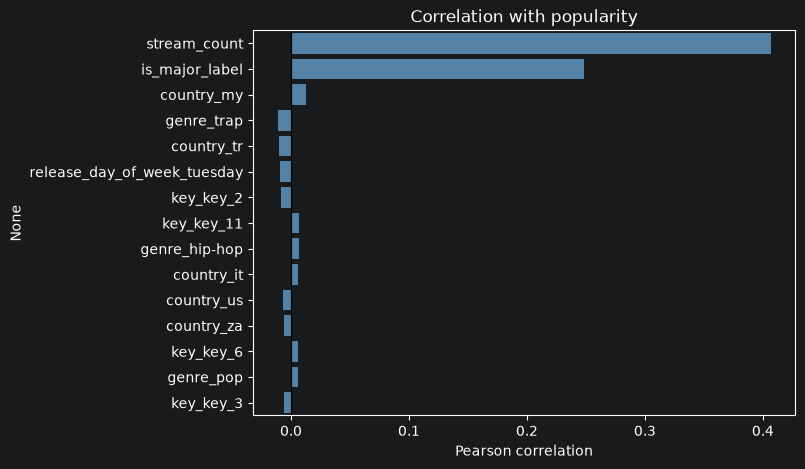

In [57]:
top = corr_sorted.head(15)
plt.figure(figsize=(7, 5))
sns.barplot(x=top.values, y=top.index, color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with popularity")
plt.xlabel("Pearson correlation")
plt.show()

As we can see there is barely any correlation between ```popularity``` and the rest of the data, except than ```stream count```. This is to be expected since it should be hard to find any correlation between a musics audio features, such as its danceability, energy, etc, and how successful it is.

## Step 2: Features and target

---

Our target y is popularity. X is all the other columns left after cleaning. IDs and names were already removed during cleaning, since they are unique per track and can’t help predict anything. We remove popularity from X so the model can’t simply read the answer. We will also declare X2, where we also remove ```stream_count```, since we see a high correlation with popularity, and X3.

In [58]:
y = df["popularity"]
X = df.drop(columns=["popularity"])
X2 = df.drop(columns=["popularity", "stream_count"])

## Step 3: Splitting and Scaling the data

---

We reuse the same code as in the previous deliverable, but remove ```stratify=y``` since we're doing regression, and it only works with classification such as hit / not a hit.

We then scale the features for KNN, because it relies on distances: without scaling, stream_count (up to 43M) would outweigh everything else. The scaler is fitted on the training set only, to avoid data leakage. Linear regression doesn’t need scaling, so we keep the unscaled data for it.

In [59]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Same split without stream_count
X2_train = X_train.drop(columns=["stream_count"])
X2_test  = X_test.drop(columns=["stream_count"])


print("train:", X_train.shape, "| test:", X_test.shape)
print("mean popularity train/test:", round(y_train.mean(), 2), round(y_test.mean(), 2))

train: (37997, 80) | test: (9500, 80)
mean popularity train/test: 28.11 28.2


In [60]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

scaler2 = StandardScaler().fit(X2_train)
X2_train_s = scaler2.transform(X2_train)
X2_test_s  = scaler2.transform(X2_test)

## Step 4: Train

---

We train two models: a linear regression, which draws the best-fitting line with the prediction is “intercept + coefficient × value”, and a KNN regressor, which predicts the average popularity of the 10 most similar tracks.

We train each model twice: with all features (X) and without stream_count (X2), to see how much of the prediction depends on streams alone.

In [61]:
#Linear regression
lin = LinearRegression().fit(X_train, y_train)
lin_preds = lin.predict(X_test)

lin2 = LinearRegression().fit(X2_train, y_train)
lin2_preds = lin2.predict(X2_test)

#KNN regression
knn = KNeighborsRegressor(n_neighbors=10).fit(X_train_s, y_train)
knn_preds = knn.predict(X_test_s)

knn2 = KNeighborsRegressor(n_neighbors=10).fit(X2_train_s, y_train)
knn2_preds = knn2.predict(X2_test_s)

print("real      :", y_test.values[:8])
print("linear    :", lin_preds[:8].round(1))
print("KNN       :", knn_preds[:8].round(1))

real      : [27. 39. 18. 28. 48. 10. 37. 32.]
linear    : [26.9 28.  26.7 27.  27.1 27.  28.  26.9]
KNN       : [37.3 28.4 29.  30.3 26.2 25.4 21.9 24.5]


## Step 5: Evaluate

---

We evaluate each model on the test set with two metrics. MSE is the average squared error between the real and predicted popularity. We also show its square root (RMSE), which is easier to read because it’s in popularity points.

R² compares each model to the average popularity: 1 is perfect, 0 is no better than the baseline, and below 0 is worse. We include that baseline in the table as a reference.

In [62]:
baseline_preds = np.full(len(y_test), y_train.mean())

models = {
    "Baseline":                      baseline_preds,
    "Linear":                        lin_preds,
    "Linear – no stream_count":      lin2_preds,
    "KNN":                           knn_preds,
    "KNN – no stream_count":         knn2_preds,
}

results = pd.DataFrame({
    "MSE":  [mean_squared_error(y_test, p) for p in models.values()],
    "RMSE": [mean_squared_error(y_test, p) ** 0.5 for p in models.values()],
    "R²":   [r2_score(y_test, p) for p in models.values()],
}, index=models.keys()).round(3)

results

,MSE,RMSE,R²
Baseline,253.292,15.915,-0.000
Linear,202.605,14.234,0.200
Linear – no stream_count,236.718,15.386,0.065
KNN,253.994,15.937,-0.003
KNN – no stream_count,274.071,16.555,-0.082


## Step 6: Interpret

---
As we can see, the linear regression with all features is the best model, with an R² of 0.20, this means that about 20% of the variation in popularity can be explained by the model. Its prediction (RMSE) are off by 14 points, 2 points better than the baseline.

The problem is that almost all of it comes from ```stream_count```, which is a strong predictor of popularity. When dropping it, the model performs worse, with an R² of 0.02 (barely better than guessing the average) and an RMSE of 15.7 points. A tracks audio feature such as genre, danceability or energy means nothing about popularity.

We can also see that KNN performs worse than the baseline, with an R² of -0.015, meaning it's worse than guessing, and an RMSE of 16 points, the same as the baseline.
As in Deliverable 3, it compares tracks using all 89 columns at once, and most of them are categories that have almost nothing to do with popularity.

In conclusion, while linear regression with all features performs better than the baseline, it is still heavily influenced by ```stream_count```. Dropping this feature results in a model that performs worse than guessing the average popularity. KNN regression also performs worse than the baseline. In summary, the models in this deliverable do not provide a reliable way to predict track popularity based on audio features alone.